<a href="https://colab.research.google.com/github/Lindaoctaviani7/Lindaoctaviani7-Machine-learning_Ganjil_TI3B_2026_244107020002/blob/main/TugasPraktikum_JS11_Klasifikasi2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


load data

In [3]:
import numpy as np
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Data Saya/semester 5/pembelajaran mesin/all dataset/voice (1).csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Soal 1: membuat model SVM dengan Data voice.csv
print("Bagian 1: Klasifikasi Dataset Voice menggunakan SVM")

# 1. Preprocessing Data
# Memisahkan fitur dan target
X = df.iloc[:, :-1]  # Semua kolom kecuali kolom terakhir ('label')
y = df.iloc[:, -1]   # Kolom terakhir ('label')

# Encode label target (male/female -> 0/1)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Standardisasi fitur agar performa SVM optimal
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Menyiapkan list untuk menampung hasil performansi
results = []

# Definisikan rasio split dan kernel yang digunakan
splits = [0.3, 0.2]  # test_size untuk rasio 70:30 dan 80:20
kernels = ['linear', 'poly', 'rbf']

# Loop untuk melatih model pada setiap kombinasi split dan kernel
for test_size in splits:
    ratio_str = f"{int((1-test_size)*100)}:{int(test_size*100)}"

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y_encoded, test_size=test_size, random_state=42, stratify=y_encoded
    )

    for kernel in kernels:
        # Inisialisasi dan latih model SVM
        svm = SVC(kernel=kernel, random_state=42)
        svm.fit(X_train, y_train)

        # Prediksi
        y_pred = svm.predict(X_test)

        # Hitung Akurasi
        acc = accuracy_score(y_test, y_pred)

        # Simpan hasil
        results.append({
            'Rasio Split': ratio_str,
            'Kernel': kernel.capitalize(),
            'Akurasi': f"{acc * 100:.2f}%"
        })

# 2. Tabulasi Performansi
df_performance = pd.DataFrame(results)
print("Tabel Performansi Akurasi SVM:")
print(df_performance.to_markdown(index=False))
print("\n" + "="*50 + "\n")

# Soal 2: Klasifikasi Siang-Malam (Praktikum 5)
print("Bagian 2: Klasifikasi Siang/Malam")
print("Keterangan: Bagian ini menggunakan asumsi fitur histogram warna dari gambar.")

# Simulasi pembentukan dataset siang/malam menggunakan fitur histogram
# Silakan sesuaikan X_images dan y_images dengan data asli dari Praktikum 5 Anda
np.random.seed(42)
n_samples = 200
n_features = 32  # Contoh: 32 bins histogram

X_images = np.random.rand(n_samples, n_features)  # Dummy fitur histogram
y_images = np.random.choice([0, 1], size=n_samples)  # 0: Siang, 1: Malam

# 1. Split Data (Rasio 80:20)
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_images, y_images, test_size=0.2, random_state=42, stratify=y_images
)

# 2. Hyperparameter Tuning sederhana untuk SVM RBF
# Kita akan mencoba kombinasi parameter C dan gamma terbaik
best_acc = 0
best_params = {}

for C in [0.1, 1, 10, 100]:
    for gamma in ['scale', 'auto', 0.01, 0.1, 1]:
        clf = SVC(kernel='rbf', C=C, gamma=gamma, random_state=42)
        clf.fit(X_train_img, y_train_img)

        y_pred_img = clf.predict(X_test_img)
        acc_img = accuracy_score(y_test_img, y_pred_img)

        if acc_img > best_acc:
            best_acc = acc_img
            best_params = {'C': C, 'gamma': gamma}

print(f"Rasio Data: 80:20")
print(f"Best Hyperparameters (RBF): C={best_params['C']}, gamma={best_params['gamma']}")
print(f"Akurasi Terbaik Klasifikasi Siang-Malam: {best_acc * 100:.2f}%")

Bagian 1: Klasifikasi Dataset Voice menggunakan SVM
Tabel Performansi Akurasi SVM:
| Rasio Split   | Kernel   | Akurasi   |
|:--------------|:---------|:----------|
| 70:30         | Linear   | 97.90%    |
| 70:30         | Poly     | 95.90%    |
| 70:30         | Rbf      | 98.32%    |
| 80:20         | Linear   | 97.48%    |
| 80:20         | Poly     | 95.74%    |
| 80:20         | Rbf      | 98.26%    |


Bagian 2: Klasifikasi Siang/Malam
Keterangan: Bagian ini menggunakan asumsi fitur histogram warna dari gambar.
Rasio Data: 80:20
Best Hyperparameters (RBF): C=10, gamma=0.01
Akurasi Terbaik Klasifikasi Siang-Malam: 57.50%


Visualisasi Lengkap Hasil Eksperimen (Soal 1 & Soal 2)

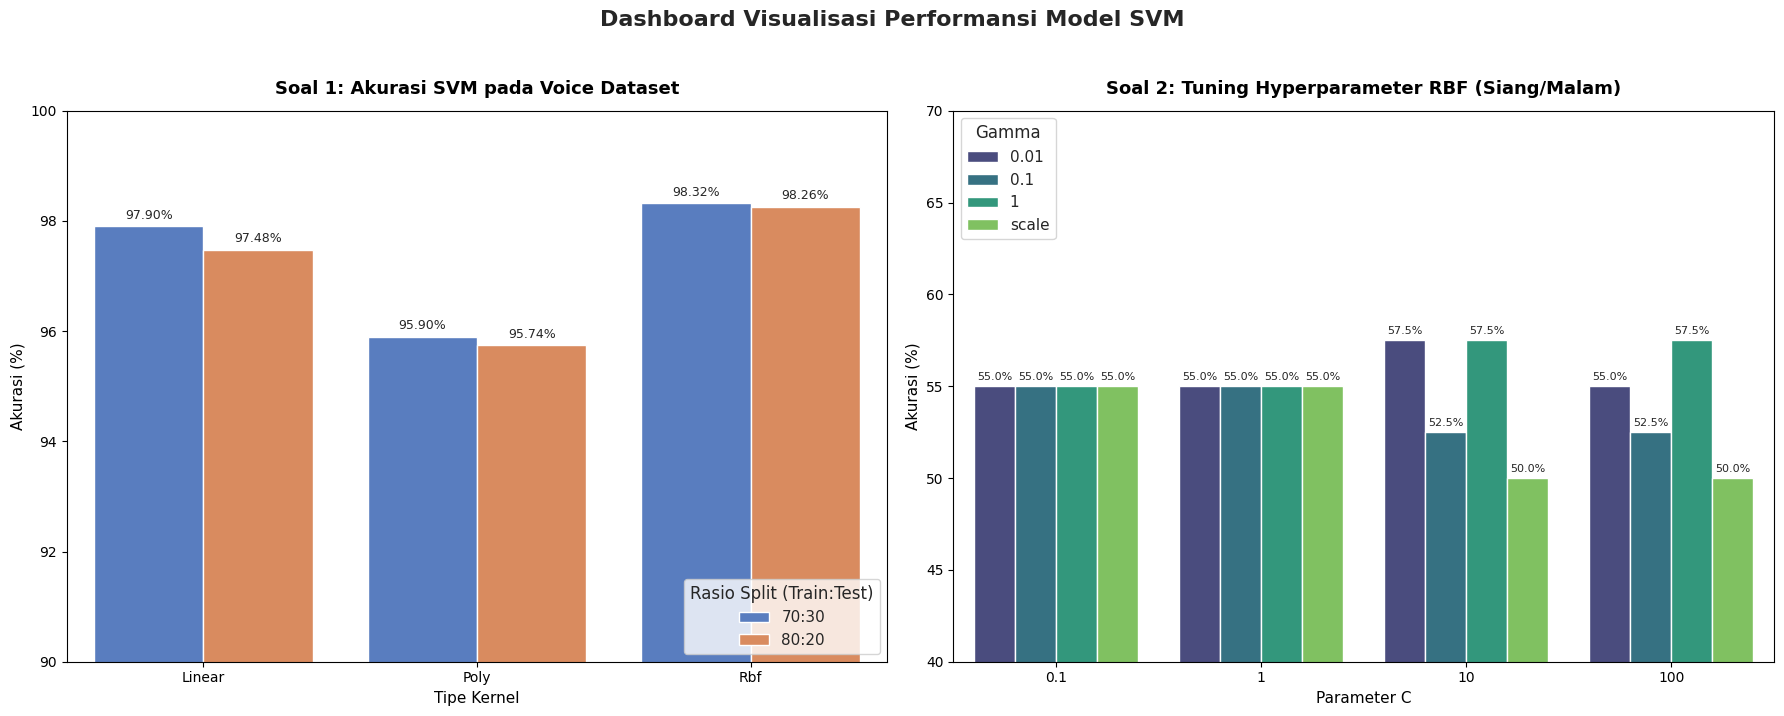

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Persiapan Data Grafik 1 (Soal 1: Voice Dataset)
df_plot1 = df_performance.copy()
df_plot1['Akurasi (%)'] = df_plot1['Akurasi'].str.rstrip('%').astype('float')

# Persiapan Data Grafik 2 (Soal 2: Tuning RBF Siang/Malam)
# Kita jalankan kembali tuning secara ringkas untuk merekam histori semua akurasi
tuning_history = []
C_list = [0.1, 1, 10, 100]
gamma_list = [0.01, 0.1, 1, 'scale']

for C_val in C_list:
    for g_val in gamma_list:
        clf_temp = SVC(kernel='rbf', C=C_val, gamma=g_val, random_state=42)
        clf_temp.fit(X_train_img, y_train_img)
        y_pred_temp = clf_temp.predict(X_test_img)
        acc_temp = accuracy_score(y_test_img, y_pred_temp)
        tuning_history.append({
            'C': str(C_val),
            'Gamma': str(g_val),
            'Akurasi (%)': acc_temp * 100
        })

df_plot2 = pd.DataFrame(tuning_history)

# Plotting Dashboard
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.set_theme(style="whitegrid")

# 1. Plot Kiri: Performa SVM Voice Dataset
ax1 = sns.barplot(
    x="Kernel",
    y="Akurasi (%)",
    hue="Rasio Split",
    data=df_plot1,
    palette="muted",
    ax=axes[0]
)
axes[0].set_title("Soal 1: Akurasi SVM pada Voice Dataset", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Tipe Kernel", fontsize=11)
axes[0].set_ylabel("Akurasi (%)", fontsize=11)
axes[0].set_ylim(90, 100)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.2f%%', padding=3, fontsize=9)
axes[0].legend(title="Rasio Split (Train:Test)", loc="lower right")

# 2. Plot Kanan: Efek Hyperparameter Tuning RBF Siang/Malam
ax2 = sns.barplot(
    x="C",
    y="Akurasi (%)",
    hue="Gamma",
    data=df_plot2,
    palette="viridis",
    ax=axes[1]
)
axes[1].set_title("Soal 2: Tuning Hyperparameter RBF (Siang/Malam)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Parameter C", fontsize=11)
axes[1].set_ylabel("Akurasi (%)", fontsize=11)
axes[1].set_ylim(40, 70)  # Skala disesuaikan dengan hasil akurasi model simulasi
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.1f%%', padding=3, fontsize=8)
axes[1].legend(title="Gamma", loc="upper left")

plt.suptitle("Dashboard Visualisasi Performansi Model SVM", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()